In [1]:
import sys, os, warnings
import numpy as np
import scipy as sp
from scipy import stats
import pandas as pd
import nibabel as nib
from tqdm import tqdm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import seaborn as sns
from brainsmash.mapgen.base import Base

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])
sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/nctpy/src'])

from src.plotting import plot_repeated_measures_violins, plot_subject_level_violins
from src.notebook import load_notebook_data

from src.timescales import create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted
from snaplab_tools.plotting.plotting import plot_correlation, plot_correlation_unity, plot_brain_surface_data
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.stats import steiger_test
from snaplab_tools.utils import winsorize

In [2]:
my_colors = get_my_colors(cat_trio=False, as_list=True)

In [3]:
def function_helper(data_dict_centiles):
    df_plot = pd.DataFrame()
    for c, condition in enumerate(data_dict_centiles.keys()):
        print(condition)
        df_tmp_1 = pd.DataFrame()
        n_subs_tmp = data_dict_centiles[condition].shape[0]
        for i in np.arange(n_subs_tmp):
            df_tmp_2 = pd.DataFrame()
            df_tmp_2['subject'] = np.zeros(10) + i
            df_tmp_2[condition] = data_dict_centiles[condition][i, :]
            df_tmp_1 = pd.concat((df_tmp_1, df_tmp_2), axis=0)
        if c == 0:
            df_plot['subject'] = df_tmp_1['subject']
        df_plot[condition] = df_tmp_1[condition]
        
    return df_plot

# Load data

In [4]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
meg_freq = '_lp-0.5hz'
use_7t = True
output_type = 'timescale_zero_crossing'
# output_type = 'timescale_zero_crossing_robust_nc2'
# output_type = 'timescale_zero_crossing_robust_nc3'
notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type,
                                   load_subject_data=True)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
Raw data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales


/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/notebook.py:266: RuntimeWarning: Mean of empty slice
  excitation = np.nanmean(gene_expression.loc[:, ampa + nmda].values, axis=1)
/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/src/notebook.py:267: RuntimeWarning: Mean of empty slice
  inhibition = np.nanmean(gene_expression.loc[:, gaba].values, axis=1)


timescale_zero_crossing


Loading timescale_zero_crossing: 100%|██████████| 3912/3912 [00:00<00:00, 9569.03it/s] 


3912


Loading timescale_zero_crossing_resids: 100%|██████████| 3912/3912 [00:00<00:00, 9796.97it/s]


3912
Number of subjects: 163
Loading connectivity data...
	sub-380036 not found
	sub-971160 not found
Loading myelin data...


In [5]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
results_dir = notebook_data['results_dir']

dict_neuro = notebook_data['supporting_data']['dict_neuro']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

print(data_dict.keys())
print(dict_neuro.keys())

dict_keys(['sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100610_task-tfMRIGAMBLINGRL_space-fsLR

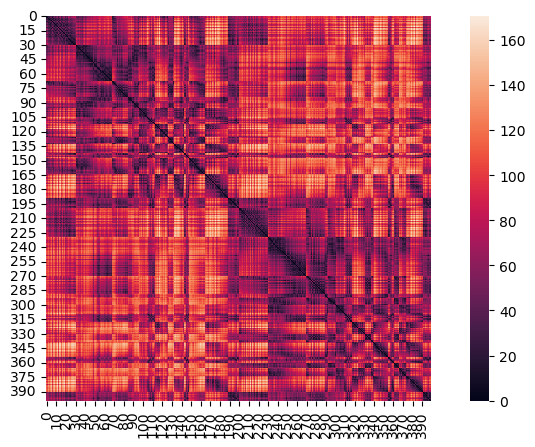

In [6]:
f, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 5))
sns.heatmap(distance_matrix, ax=ax, square=True)
plt.show()

In [7]:
timescales_processor.scan_registry.head()

,scan_string,sub,task,space,seg,ses,modality,tr,condition
0,sub-100610_task-rfMRIREST1LR_space-fsLR_seg-Sc...,100610,rfMRIREST1LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
1,sub-100610_task-rfMRIREST1RL_space-fsLR_seg-Sc...,100610,rfMRIREST1RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
2,sub-100610_task-rfMRIREST2LR_space-fsLR_seg-Sc...,100610,rfMRIREST2LR,fsLR,Schaefer4007,1,MRI3T,0.72,rest
3,sub-100610_task-rfMRIREST2RL_space-fsLR_seg-Sc...,100610,rfMRIREST2RL,fsLR,Schaefer4007,1,MRI3T,0.72,rest
4,sub-100610_task-tfMRIWMLR_space-fsLR_seg-Schae...,100610,tfMRIWMLR,fsLR,Schaefer4007,1,MRI3T,0.72,task


In [8]:
subject_ids = timescales_processor.scan_registry['sub'].unique()
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 163


# BrainSMASH null

In [9]:
if dataset == 'HCP-YA':
    neuro_cols = ['Myelin', 'Gene (PC1)', 'Strength']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'Strength', 'Gene_EI_ratio']
    # neuro_cols = ['Gene (PC1)', 'Myelin', 'SC_Degree']
    # neuro_cols = ['Gene_PVALB', 'Gene_GRIA1', 'Gene_GRIN2A', 'Gene_GABRA1', 'Gene_GABRA3']
    # neuro_cols = ['Gene_GABRA1', 'Gene_GABRA2', 'Gene_GABRA3', 'Gene_GABRA4', 'Gene_GABRA5']
else:
    neuro_cols = ['Gene (PC1)']

In [10]:
n_permutations = 10000
# n_permutations = 100

brain_map_surrogates = dict()
for neuro_str in neuro_cols:
    out_file = os.path.join(timescales_processor.output_dir, 'data', 'brain_map_surrogates_{0}.npy'.format(neuro_str.replace(' ', '_')))
    if os.path.exists(out_file):
        print(f'Loading {neuro_str}')
        brain_map_surrogates[neuro_str] = np.load(out_file)
    else:
        print(f'Running {neuro_str}')
        base = Base(x=dict_neuro[neuro_str], D=distance_matrix)
        brain_map_surrogates[neuro_str] = base(n=n_permutations)

        np.save(out_file, brain_map_surrogates[neuro_str])
        
    print(neuro_str, brain_map_surrogates[neuro_str].shape)

Loading Myelin
Myelin (10000, 400)
Loading Gene (PC1)
Gene (PC1) (10000, 400)
Loading Strength
Strength (10000, 400)


# Data for figures

In [11]:
collapse_hcp = True
sort_by_median = True

if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True,
                                                        average_3t_tasks=True)
        if dataset == 'HCP-YA' and use_7t:
            custom_order = ['Rest', 'Movies', 'Tasks']
            df_ints = df_ints[custom_order]
        elif dataset == 'HCP-YA' and not use_7t:
            custom_order = ['Rest', 'Tasks']
            df_ints = df_ints[custom_order]
    else:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        # average_7t_rest=True, average_3t_rest=True,
                                                        average_all_rest=True,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                    average_meg_rest=True, average_meg_task=True)
else:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median)

data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_centiles = convert_data_dict(data_dict, timescales_processor.scan_registry, brain_map=dict_neuro['SA_Axis'])
if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        data_dict_centiles = average_data_dict_converted(data_dict_centiles, average_3t_tasks=True, average_7t_movies=True, average_all_rest=True)
        data_dict_centiles = {key: data_dict_centiles[key] for key in custom_order if key in data_dict_centiles}
        data_dict_converted = average_data_dict_converted(data_dict_converted, average_3t_tasks=True, average_7t_movies=True, average_all_rest=True)
        data_dict_converted = {key: data_dict_converted[key] for key in custom_order if key in data_dict_converted}
    else:
        data_dict_centiles = average_data_dict_converted(data_dict_centiles, 
                                                        #  average_7t_rest=True, average_3t_rest=True,
                                                        average_all_rest=True,
                                                         average_3t_task_pairs=True, average_7t_movies=True)
        
        data_dict_converted = average_data_dict_converted(data_dict_converted, 
                                                        #   average_7t_rest=True, average_3t_rest=True,
                                                        average_all_rest=True,
                                                          average_3t_task_pairs=True, average_7t_movies=True)
elif which_modality == 'MEG' and 'HCP' in dataset:
    data_dict_centiles = average_data_dict_converted(data_dict_centiles,
                                                     average_meg_rest=True, average_meg_task=True)

Scan: task-rfMRIREST1LR
  Number of subjects: 163
  Mean INT range: [2.721, 13.640]
Scan: task-rfMRIREST1RL
  Number of subjects: 163
  Mean INT range: [2.823, 14.789]
Scan: task-rfMRIREST2LR
  Number of subjects: 163
  Mean INT range: [3.039, 15.942]
Scan: task-rfMRIREST2RL
  Number of subjects: 163
  Mean INT range: [3.154, 14.413]
Scan: task-tfMRIWMLR
  Number of subjects: 163
  Mean INT range: [1.864, 5.844]
Scan: task-tfMRIWMRL
  Number of subjects: 163
  Mean INT range: [1.855, 5.627]
Scan: task-tfMRIEMOTIONLR
  Number of subjects: 163
  Mean INT range: [2.200, 7.125]
Scan: task-tfMRIEMOTIONRL
  Number of subjects: 163
  Mean INT range: [2.120, 7.394]
Scan: task-tfMRIGAMBLINGLR
  Number of subjects: 163
  Mean INT range: [2.182, 7.363]
Scan: task-tfMRIGAMBLINGRL
  Number of subjects: 163
  Mean INT range: [2.288, 7.399]
Scan: task-tfMRILANGUAGELR
  Number of subjects: 163
  Mean INT range: [2.823, 10.341]
Scan: task-tfMRILANGUAGERL
  Number of subjects: 163
  Mean INT range: [2.6

# Prefigures

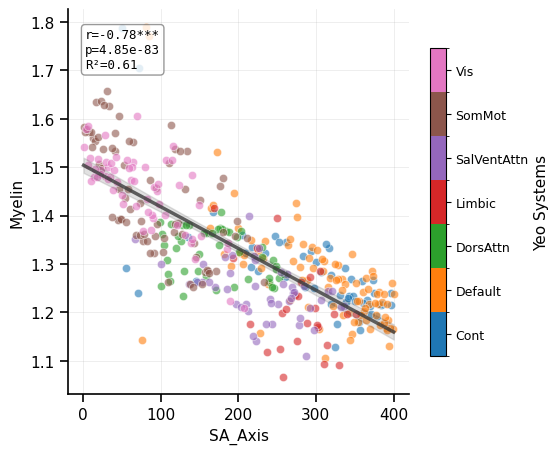

In [12]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=1, sharex=False, sharey=False, figsize=(5.5, 5))
    plot_correlation(dict_neuro['SA_Axis'], dict_neuro['Myelin'], axes,
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='SA_Axis', y_label='Myelin', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
    fig.savefig(os.path.join(results_dir, 'sa_myelin_corr.png'), bbox_inches='tight', dpi=300, transparent=True)

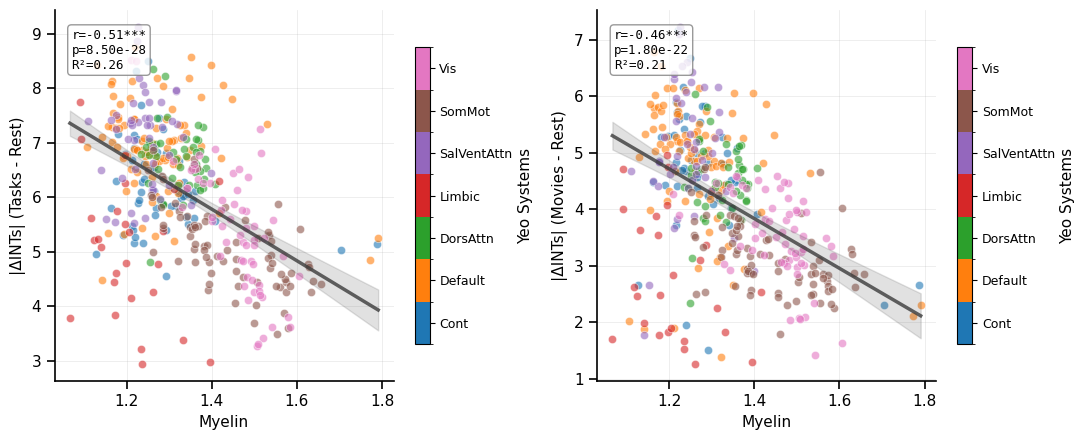

In [13]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=False, figsize=(11, 4.5))
    plot_correlation(dict_neuro['Myelin'], np.abs(df_ints['Tasks'] - df_ints['Rest']), axes[0],
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='Myelin', y_label='|ΔINTs| (Tasks - Rest)', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')

    plot_correlation(dict_neuro['Myelin'], np.abs(df_ints['Movies'] - df_ints['Rest']), axes[1],
                    data_group=np.asarray(yeo_systems), show_stats=True, fontsize=11, method='pearson',
                    size=35, x_label='Myelin', y_label='|ΔINTs| (Movies - Rest)', cbar_label='Yeo Systems',
                    auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
    
    fig.tight_layout()
    fig.savefig(os.path.join(results_dir, 'myelin_INT_deflection_corr.png'), bbox_inches='tight', dpi=300, transparent=True)

In [14]:
df_ints

,Rest,Movies,Tasks
0,10.135920,7.115031,4.315951
1,12.254632,7.987730,3.729571
2,10.839969,7.349693,5.285890
3,10.596503,7.243865,4.271043
4,10.813282,6.796012,5.213006
...,...,...,...
395,13.054202,7.358896,4.863681
396,11.485000,6.647239,4.755828
397,9.724601,6.636503,4.525399
398,12.188742,7.440184,4.865890


# Figure 1: Modulation of INTs vs SA axis

### Plot timescales brain plot (average)

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


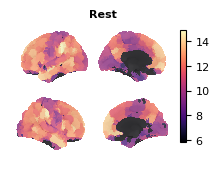

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


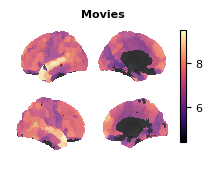

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

/mnt/storage_ssd_raid/research_projects/snaplab_tools/snaplab_tools/plotting/plotting.py:1070: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.0, h_pad=-0.5, w_pad=-0.5)


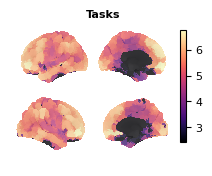

In [15]:
if dataset == 'HCP-YA':
    for column in df_ints.columns:
        file_str = os.path.join(results_dir, f'timescales_brain_{column}.png')
        if not os.path.isfile(file_str):
            fig, axes = plot_brain_surface_data(
                data_vector=df_ints[column],
                parcellation='schaefer_400',
                cmap='magma',
                symmetric_cbar=False,
                title=column, figsize=(2.1, 1.6), fontsize=8, cbar_label=None
            )
            plt.show()
            fig.savefig(file_str, bbox_inches='tight', dpi=300, transparent=True)

### Plot timescales, average (regional) & subject-level (SA centiles)

In [16]:
df_ints.columns

Index(['Rest', 'Movies', 'Tasks'], dtype='object')

In [17]:
df_corr = pd.DataFrame(index=subject_ids)
df_corr.index.name = 'subject_ids'
neuro_col = 'SA_Axis'
# neuro_col = 'Myelin'
for int_col in data_dict_converted.keys():
    print(int_col)
    for i in tqdm(np.arange(n_subs)):
        subject_id = subject_ids[i]
        corr = sp.stats.spearmanr(data_dict_converted[int_col][i], dict_neuro[neuro_col])
        column_label = '({0},{1})'.format(neuro_col.lower(), int_col.lower())
        df_corr.loc[subject_id, column_label] = corr[0]
        
df_corr.head()

Rest


100%|██████████| 163/163 [00:00<00:00, 4419.37it/s]


Movies


100%|██████████| 163/163 [00:00<00:00, 3881.87it/s]


Tasks


100%|██████████| 163/163 [00:00<00:00, 3812.98it/s]


,"(sa_axis,rest)","(sa_axis,movies)","(sa_axis,tasks)"
subject_ids,,,
100610,0.513982,0.424964,0.369179
102311,0.129665,0.199734,0.508964
102816,0.515530,-0.062685,0.290444
104416,0.467785,0.226655,0.218554
105923,0.218670,0.427196,0.385718


In [18]:
r_xy = sp.stats.pearsonr(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,movies)'])[0]
r_xz = sp.stats.pearsonr(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,tasks)'])[0]
r_yz = sp.stats.pearsonr(df_corr['(sa_axis,tasks)'], df_corr['(sa_axis,movies)'])[0]
# r_xy = sp.stats.pearsonr(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,movies)'])[0]
# r_xz = sp.stats.pearsonr(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,wm)'])[0]
# r_yz = sp.stats.pearsonr(df_corr['(sa_axis,wm)'], df_corr['(sa_axis,movies)'])[0]
n = df_corr.shape[0]
steiger_test(r_xy, r_xz, r_yz, n, alternative='greater')

(np.float64(1.4574545490951536), np.float64(0.07249547441429982))

Data shape: (400, 3)
Conditions: ['Rest', 'Movies', 'Tasks']


/tmp/ipykernel_831877/999259634.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([''])


Rest
Movies
Tasks
Number of subjects: 163
Selected regions: [0 1 2 3 4 5 6 7 8 9]
Conditions: ['Rest', 'Movies', 'Tasks']
Filtered data shape: (1630, 5)
Expected rows: 1630
Sorted conditions by median (descending):
  Rest: median = 11.2186
  Movies: median = 7.1562
  Tasks: median = 5.1067
Fitting polynomial trends to distribution means...
  Rest: Best fit = Quadratic (R² = 0.920)
  Movies: Best fit = Quadratic (R² = 0.769)
  Tasks: Best fit = Quadratic (R² = 0.885)
TtestResult(statistic=np.float64(10.762877505230337), pvalue=np.float64(1.0144984753958004e-20), df=np.int64(162))
TtestResult(statistic=np.float64(8.198100713909959), pvalue=np.float64(7.058646545867231e-14), df=np.int64(162))
TtestResult(statistic=np.float64(-3.311345737682523), pvalue=np.float64(0.0011448183616088463), df=np.int64(162))
Data shape: (163, 3)
Conditions: ['Rest', 'Movies', 'Tasks']


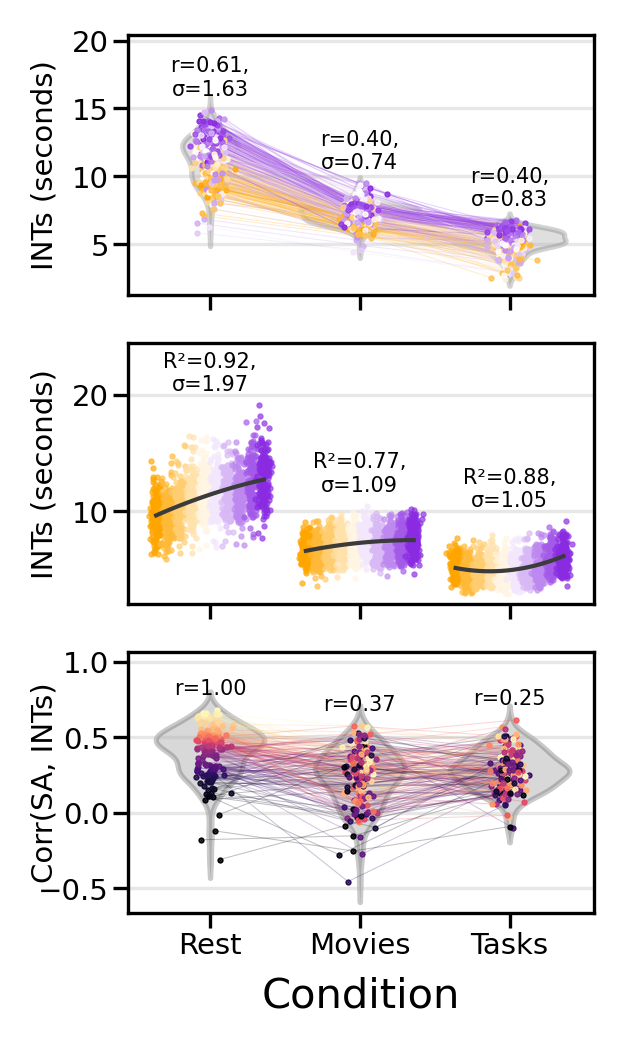

In [19]:
plt.rcParams.update({'font.size': 7})
if 'B' in output_type:
    ylabel_text = 'INTs (B)'
else:
    ylabel_text = 'INTs (seconds)'

fig, axes = plt.subplots(nrows=3, ncols=1, sharex=True, sharey=False,
                         figsize=(len(df_ints.columns)*.7, 3.5),
                         dpi=300)
                        #  dpi=300, gridspec_kw={'height_ratios':[2, 2, 1]})
axes[0] = plot_repeated_measures_violins(df_ints, axes[0], color_vector=dict_neuro['SA_Axis'], colormap='sydnor_sa', add_colorbar=False,
                                         point_alpha=1, line_alpha=0.3, point_size=0.25, line_width=0.25, violin_alpha=0.25,
                                         correlation_method='pearson', annotate_variance=True)
axes[0].set_xticklabels([''])
axes[0].set_xlabel('')

df_centiles = function_helper(data_dict_centiles)
if dataset == 'WAND':
    df_centiles['reversallearning'] = winsorize(df_centiles['reversallearning'])
axes[1], trend_results = plot_subject_level_violins(df_centiles, axes[1], np.arange(10),
                                                    point_alpha=0.75, point_size=0.25,
                                                    show_violins=False, show_lines=False, fit_trends=True,
                                                    show_r2_annotation=True, annotate_variance=True,
                                                    hide_legend=True, sort_by_median=sort_by_median)
axes[1].set_xlabel('')

df_plot = df_corr[['(sa_axis,rest)', '(sa_axis,movies)', '(sa_axis,tasks)']].reset_index(drop=True)
# df_plot = df_corr[['(sa_axis,rest)', '(sa_axis,movies)', '(sa_axis,wm)']].reset_index(drop=True)
df_plot.columns = ['Rest', 'Movies', 'Tasks']
# df_plot = df_corr.reset_index(drop=True)
# df_plot.columns = df_ints.columns
df_plot = df_plot.loc[~df_plot.isna().any(axis=1), :]
print(sp.stats.ttest_rel(df_plot['Rest'], df_plot['Movies']))
print(sp.stats.ttest_rel(df_plot['Rest'], df_plot['Tasks']))
print(sp.stats.ttest_rel(df_plot['Movies'], df_plot['Tasks']))
plot_repeated_measures_violins(df_plot, axes[2], 
                               color_vector=df_plot['Rest'], 
                               add_colorbar=False, correlation_method='pearson', colormap='magma',
                               point_alpha=1, line_alpha=0.25, point_size=0.25, line_width=0.25, violin_alpha=0.3)
axes[2].set_ylabel('Corr(SA, INTs)', fontsize=7)

if dataset == 'HCP-YA':
    axes[0].set_ylabel(ylabel_text, fontsize=7)
    axes[1].set_ylabel(ylabel_text, fontsize=7)
    # axes[2].legend(fontsize=5)
else:
    axes[0].set_ylabel('')
    axes[1].set_ylabel('')
    axes[2].set_ylabel('')

for ax in axes:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    if 'B' in output_type:
        ax.yaxis.set_label_coords(-0.35, 0.5)
    else:
        ax.yaxis.set_label_coords(-0.15, 0.5)

plt.tight_layout()
if which_modality == 'MEG':
    file_label = f'{output_type}_MEG{meg_freq}.png'
else:
    file_label = f'{output_type}.png'
fig.savefig(os.path.join(results_dir, file_label), bbox_inches='tight', dpi=300, transparent=True)
plt.show()

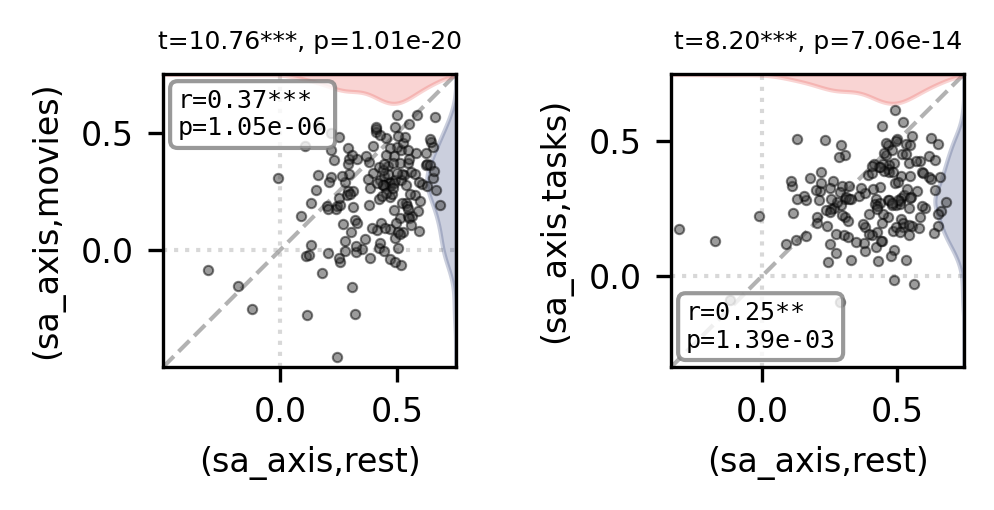

In [20]:
if dataset == 'HCP-YA':
    fig, axes = plt.subplots(nrows=1, ncols=2, sharex=False, sharey=False, figsize=(4, 1.5), dpi=300)
    plot_correlation_unity(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,movies)'], axes[0],
                        marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                        show_marginals=True, show_correlation=True, correlation_type='pearson', grid=False, size=5, fontsize=8)
    plot_correlation_unity(df_corr['(sa_axis,rest)'], df_corr['(sa_axis,tasks)'], axes[1],
                        marginal_color_x=my_colors[0], marginal_color_y=my_colors[1],
                        show_marginals=True, show_correlation=True, correlation_type='pearson', grid=False, size=5, fontsize=8)
    plt.tight_layout(pad=0, w_pad=-5, h_pad=0)
    fig.savefig(os.path.join(results_dir, 'neuroanatomy_INTs_correlations_unity.png'), bbox_inches='tight', dpi=300, transparent=True)
    plt.show()